# 02 · Cruce RNDC + SICE-TAC y construcción de la etiqueta

Este notebook toma los dos archivos limpios del notebook 01, los cruza por municipio de origen y destino, y decide para cada viaje si el pago alcanzó el costo de referencia.

Antes de entrar en código, una aclaración sobre el momento de la predicción. La etiqueta se calcula comparando pago y costo, y esa comparación solo sirve para aprender del histórico. El modelo del notebook 03 se usa en otro momento: cuando llega una oferta de carga y todavía no se conoce el flete final. En ese momento se saben el origen, el destino, los kilos, el tipo de mercancía y si la carga es refrigerada o peligrosa. El pago no se sabe. Por eso el pago y el costo construyen la etiqueta pero nunca entran como predictores, y viven en un archivo aparte.

Entran: `rndc_limpio_dic2025.csv.gz` y `sicetac_costos_c2_dic2025.csv`.

Salen: `dataset_modelo_dic2025.csv` (lo único que lee el modelo), `dataset_auditoria_dic2025.csv` (todo, para revisar), `bitacora_cruce.csv`, `fig_target.png` y `fig_rentable_km.png`.

## 1. Carga y cruce

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = '/content' if os.path.exists('/content') else '.'
rndc = pd.read_csv(f'{BASE}/rndc_limpio_dic2025.csv.gz')
costos = pd.read_csv(f'{BASE}/sicetac_costos_c2_dic2025.csv')

bitacora = []
def anotar(paso, antes, despues, por_que):
    bitacora.append({'paso': paso, 'filas_antes': antes, 'filas_despues': despues,
                     'quitadas': antes - despues, 'por_que': por_que})
    print(f'{paso:48s} {antes:>7,} -> {despues:>7,}  (-{antes - despues:,})')

df = rndc.merge(costos, left_on=['CODMUNICIPIOORIGEN', 'CODMUNICIPIODESTINO'],
                right_on=['ORIGEN', 'DESTINO'], how='inner').drop(columns=['ORIGEN', 'DESTINO'])
anotar('Cruce con una ruta del SICE-TAC', len(rndc), len(df), 'El SICE-TAC no tiene costo parametrizado para todas las parejas de municipios')
print(f'Cobertura del cruce: {len(df) / len(rndc):.1%}')

Cruce con una ruta del SICE-TAC                   37,643 ->  21,094  (-16,549)
Cobertura del cruce: 56.0%


Cerca de 44 % de los viajes limpios no encuentra su ruta en el SICE-TAC. Eso pasa porque el Ministerio no parametriza todas las combinaciones de municipios, sobre todo las de pueblos pequeños. No hay forma de inventar ese costo, así que esos viajes quedan por fuera. Hay que decirlo en el informe como limitación: el modelo aprende de las rutas que el SICE-TAC sí costea.

## 2. Costo de referencia de cada viaje

A los viajes refrigerados les toca el costo de carga refrigerada de su ruta; a todos los demás, el de carga general. La carga peligrosa, los semovientes y los desechos no tienen un costo propio en el SICE-TAC para este vehículo, así que también usan el de carga general; eso hay que tenerlo en cuenta al leer sus coeficientes. La fórmula y el porqué están en el notebook 01.

In [2]:
df['COSTO_REFERENCIA'] = np.where(df['NATURALEZACARGA'] == 'Refrigerada',
                                  df['COSTO_REFRIGERADA'], df['COSTO_GENERAL'])
df['RAZON_PAGO_COSTO'] = df['VALORESPAGADOS'] / df['COSTO_REFERENCIA']
df['RAZON_KM'] = df['KILOMETROS'] / df['KM_SICETAC']
print(df[['RAZON_PAGO_COSTO', 'RAZON_KM']].describe(percentiles=[.005, .01, .5, .99, .995]).round(2))

       RAZON_PAGO_COSTO  RAZON_KM
count          21094.00  21094.00
mean               1.36      0.97
std                1.33      0.09
min                0.03      0.34
0.5%               0.32      0.55
1%                 0.45      0.60
50%                1.13      0.99
99%                4.36      1.17
99.5%              5.79      1.21
max               69.92      2.00


## 3. Viajes que no cuadran entre las dos fuentes

Ahora que cada viaje tiene su costo se pueden ver errores que antes no se veían, como pagos exagerados o demasiado bajos para la distancia. Usamos dos reglas fijas, pensadas para atrapar errores de digitación y no para recortar la distribución.

La primera compara los kilómetros que reporta el RNDC con los de la ruta oficial del SICE-TAC. En casi todos los viajes coinciden (la mediana de la razón es 0,99). Cuando uno es menos de la mitad o más del doble del otro, el viaje no hizo esa ruta o los kilómetros están mal, y sale.

La segunda mira la razón entre lo pagado y el costo. Un viaje pagado a menos de la cuarta parte de su costo, o a más de seis veces, casi seguro tiene un cero de más o de menos en el pago; el caso más extremo estaba pagado a 70 veces su costo. Estos viajes son pocos pero mueven mucho los promedios y las gráficas. Son límites fijos, no aprendidos de los datos, así que no generan fuga.

In [3]:
n = len(df); df = df[df['RAZON_KM'].between(0.5, 2)]
anotar('Km del RNDC coherentes con la ruta oficial', n, len(df), 'Fuera de 0,5 a 2 veces la distancia oficial: ruta distinta o km mal digitados')

n = len(df); df = df[df['RAZON_PAGO_COSTO'].between(0.25, 6)]
anotar('Pago entre 0,25 y 6 veces el costo', n, len(df), 'Fuera de ese rango casi siempre es un cero de más o de menos en el pago')
df = df.reset_index(drop=True)

Km del RNDC coherentes con la ruta oficial        21,094 ->  21,038  (-56)
Pago entre 0,25 y 6 veces el costo                21,038 ->  20,868  (-170)


## 4. La etiqueta y qué tan sensible es

`RENTABLE = 1` si el pago cubre el costo de referencia. Sobre la palabra: el SICE-TAC estima un costo eficiente de operación, así que “rentable” aquí quiere decir que el pago cubre ese costo, no que el viaje deje una utilidad determinada. Además guardamos tres versiones alternativas, solo para el archivo de auditoría y el análisis de sensibilidad: con la carrocería de carga general más barata, con la más cara y con la fórmula de la primera entrega. Así se puede medir con números qué tanto depende la etiqueta del supuesto de carrocería.

In [4]:
df['RENTABLE'] = (df['VALORESPAGADOS'] >= df['COSTO_REFERENCIA']).astype(int)
es_ref = df['NATURALEZACARGA'] == 'Refrigerada'
costo_min = np.where(es_ref, df['COSTO_REFRIGERADA'], df['COSTO_GENERAL_MIN'])
costo_max = np.where(es_ref, df['COSTO_REFRIGERADA'], df['COSTO_GENERAL_MAX'])
df['RENTABLE_CARROCERIA_BARATA'] = (df['VALORESPAGADOS'] >= costo_min).astype(int)
df['RENTABLE_CARROCERIA_CARA'] = (df['VALORESPAGADOS'] >= costo_max).astype(int)
df['RENTABLE_FORMULA_ANTERIOR'] = (df['VALORESPAGADOS'] >= df['COSTO_FORMULA_ANTERIOR']).astype(int)
df['RUTA'] = df['MUNICIPIOORIGEN'] + ' - ' + df['MUNICIPIODESTINO']

sens = pd.DataFrame({
    'Etiqueta': ['Principal (mediana de carga general)', 'Carrocería más barata', 'Carrocería más cara', 'Fórmula de la primera entrega'],
    '% rentables': [df[c].mean() for c in ['RENTABLE', 'RENTABLE_CARROCERIA_BARATA', 'RENTABLE_CARROCERIA_CARA', 'RENTABLE_FORMULA_ANTERIOR']],
    '% viajes que cambian frente a la principal': [0.0] + [(df[c] != df['RENTABLE']).mean()
        for c in ['RENTABLE_CARROCERIA_BARATA', 'RENTABLE_CARROCERIA_CARA', 'RENTABLE_FORMULA_ANTERIOR']],
})
sens.to_csv('sensibilidad_etiqueta.csv', index=False)
print(f"Viajes con pago entre 0,9 y 1,1 veces el costo: {df['RAZON_PAGO_COSTO'].between(0.9, 1.1).mean():.1%}")
sens.round(3)

Viajes con pago entre 0,9 y 1,1 veces el costo: 24.8%


,Etiqueta,% rentables,% viajes que cambian frente a la principal
0,Principal (mediana de carga general),0.677,0.000
1,Carrocería más barata,0.677,0.000
2,Carrocería más cara,0.596,0.081
3,Fórmula de la primera entrega,0.568,0.172


Con la corrección, cerca de dos tercios de los viajes resultan rentables. La incertidumbre por carrocería ya es pequeña: la carrocería más barata da la misma etiqueta que la principal (tres de las cuatro carrocerías de carga general cuestan lo mismo) y la más cara, el furgón, cambia la etiqueta de 8 % de los viajes, frente al 31 % que cambiaba antes. Y la fórmula de la primera entrega etiquetaba distinto a uno de cada seis viajes, sobre todo los largos.

## 5. Roles de las variables

| Grupo | Variables | Para qué |
|---|---|---|
| Construyen la etiqueta | VALORESPAGADOS, COSTO_REFERENCIA y sus componentes (horas, valor hora, costos por carrocería) | Solo para calcular RENTABLE. Nunca entran al modelo |
| Predictores | KILOMETROS, KILOGRAMOS, CAPITULO, NATURALEZACARGA, DEPARTAMENTOORIGEN, DEPARTAMENTODESTINO | Se conocen cuando llega la oferta, antes de pactar el flete |
| Auxiliar | RUTA | No entra al modelo; sirve para que una ruta no quede a la vez en entrenamiento y validación |
| Fuera | MES | Todo es diciembre, no varía |
| Fuera | Velocidad del artículo (km ÷ horas) | Las horas salen del SICE-TAC, la misma fuente del costo; además ahora definen las horas logísticas |
| Fuera | Municipios | Demasiadas categorías; la ubicación entra por departamento |

In [5]:
COLS_TARGET = ['VALORESPAGADOS', 'COSTO_REFERENCIA', 'RAZON_PAGO_COSTO', 'COSTO_GENERAL', 'COSTO_GENERAL_MIN',
               'COSTO_GENERAL_MAX', 'COSTO_REFRIGERADA', 'COSTO_FORMULA_ANTERIOR', 'HORAS_TRANSITO', 'HORAS_LOGISTICAS']
COLS_PRED = ['KILOMETROS', 'KILOGRAMOS', 'CAPITULO', 'NATURALEZACARGA', 'DEPARTAMENTOORIGEN', 'DEPARTAMENTODESTINO']

modelo = df[COLS_PRED + ['RUTA', 'RENTABLE']]
assert not set(COLS_TARGET) & set(modelo.columns), 'Fuga: una variable de la etiqueta quedó en el archivo del modelo'
modelo.to_csv('dataset_modelo_dic2025.csv', index=False)
df.to_csv('dataset_auditoria_dic2025.csv', index=False)
pd.DataFrame(bitacora).to_csv('bitacora_cruce.csv', index=False)
print('Dataset del modelo:', modelo.shape, '| rutas:', modelo['RUTA'].nunique())
print(modelo['RENTABLE'].value_counts(normalize=True).round(4))

Dataset del modelo: (20868, 8) | rutas: 4146
RENTABLE
1    0.6768
0    0.3232
Name: proportion, dtype: float64


## 6. Figuras para el informe

La primera muestra el balance de clases y cómo se construye la etiqueta: cada punto es un viaje, y la diagonal separa los rentables de los que no. Valida la etiqueta; no quiere decir que pago y costo entren al modelo.

La segunda compara la fórmula anterior con la corregida por tramo de distancia. Es la figura que explica por qué cambió el proyecto: con la fórmula vieja casi ningún viaje largo parecía rentable.

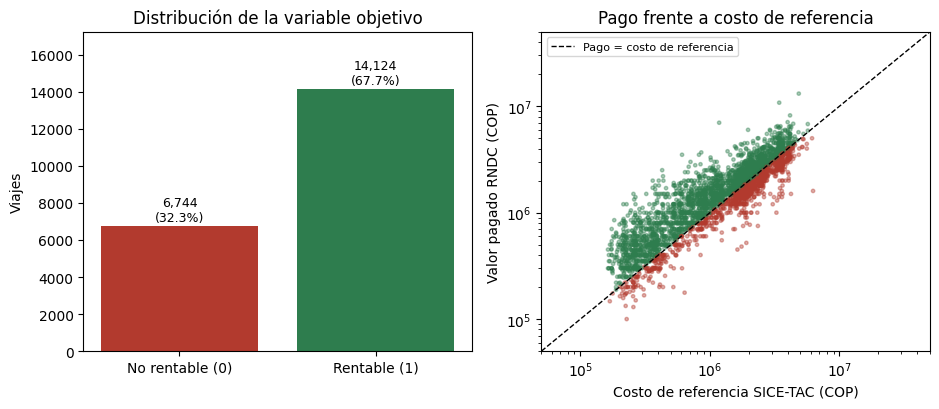

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
cnt = df['RENTABLE'].value_counts().sort_index()
axes[0].bar(['No rentable (0)', 'Rentable (1)'], cnt.values, color=['#B23A2E', '#2E7D4E'])
axes[0].set_ylim(0, cnt.max() * 1.22)
for i, v in enumerate(cnt.values):
    axes[0].text(i, v + cnt.max() * 0.02, f'{v:,}\n({v / len(df):.1%})', ha='center', fontsize=9)
axes[0].set_title('Distribución de la variable objetivo'); axes[0].set_ylabel('Viajes')
mu = df.sample(min(4000, len(df)), random_state=1)
axes[1].scatter(mu['COSTO_REFERENCIA'], mu['VALORESPAGADOS'], s=6, alpha=0.4,
                c=mu['RENTABLE'].map({0: '#B23A2E', 1: '#2E7D4E'}))
lims = [5e4, 5e7]; axes[1].plot(lims, lims, 'k--', lw=1, label='Pago = costo de referencia')
axes[1].set_xscale('log'); axes[1].set_yscale('log'); axes[1].set_xlim(lims); axes[1].set_ylim(lims)
axes[1].set_xlabel('Costo de referencia SICE-TAC (COP)'); axes[1].set_ylabel('Valor pagado RNDC (COP)')
axes[1].set_title('Pago frente a costo de referencia'); axes[1].legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.savefig('fig_target.png', dpi=200); plt.show()

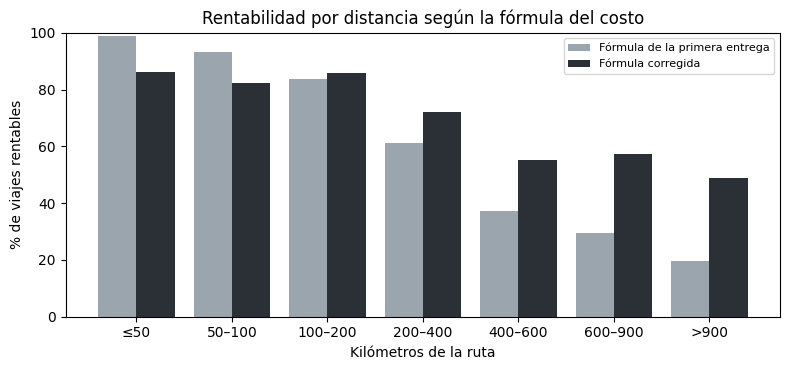

,RENTABLE,RENTABLE_FORMULA_ANTERIOR,viajes
KM_SICETAC,,,
≤50,0.861,0.990,2863
50–100,0.823,0.931,1453
100–200,0.857,0.837,2496
200–400,0.722,0.613,4017
400–600,0.551,0.371,5196
600–900,0.574,0.294,2328
>900,0.487,0.197,2515


In [7]:
tramos = pd.cut(df['KM_SICETAC'], [0, 50, 100, 200, 400, 600, 900, 3000],
                labels=['≤50', '50–100', '100–200', '200–400', '400–600', '600–900', '>900'])
t = df.groupby(tramos, observed=True)[['RENTABLE', 'RENTABLE_FORMULA_ANTERIOR']].mean()
t['viajes'] = df.groupby(tramos, observed=True).size()
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(t))
ax.bar(x - 0.2, t['RENTABLE_FORMULA_ANTERIOR'] * 100, 0.4, color='#9AA5AD', label='Fórmula de la primera entrega')
ax.bar(x + 0.2, t['RENTABLE'] * 100, 0.4, color='#2A3036', label='Fórmula corregida')
ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_xlabel('Kilómetros de la ruta')
ax.set_ylabel('% de viajes rentables'); ax.set_ylim(0, 100); ax.legend(fontsize=8)
ax.set_title('Rentabilidad por distancia según la fórmula del costo')
plt.tight_layout(); plt.savefig('fig_rentable_km.png', dpi=200); plt.show()
t.round(3)

## 7. El salto de las 8 horas

La norma reconoce 4 horas logísticas en rutas de hasta 8 horas de tránsito y 8 en las más largas. Eso hace que el costo de referencia dé un salto justo en ese punto, y la proporción de viajes que cubren el costo cae de golpe. Parte de lo que después parece un efecto de la distancia es esta regla del costo y no el comportamiento del mercado, y así hay que leerlo.

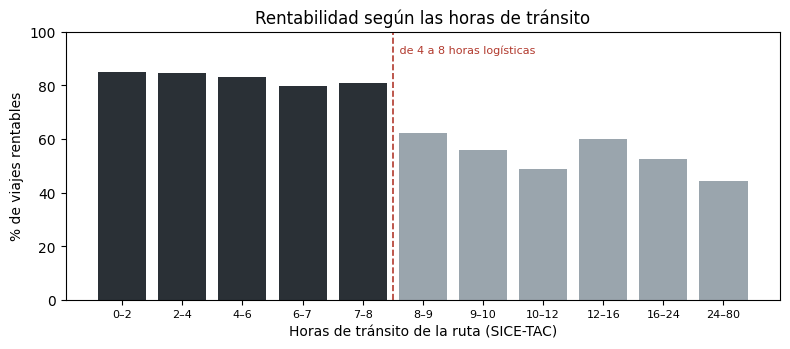

,% rentables,viajes
HORAS_TRANSITO,,
"(0, 2]",0.852,3807
"(2, 4]",0.845,2156
"(4, 6]",0.831,2009
"(6, 7]",0.797,970
"(7, 8]",0.810,574
"(8, 9]",0.624,696
"(9, 10]",0.559,1259
"(10, 12]",0.489,3192
"(12, 16]",0.602,2771


In [8]:
cortes = [0, 2, 4, 6, 7, 8, 9, 10, 12, 16, 24, 80]
horas = pd.cut(df['HORAS_TRANSITO'], cortes)
th = df.groupby(horas, observed=True)['RENTABLE'].agg(['mean', 'size']).rename(columns={'mean': '% rentables', 'size': 'viajes'})
th.to_csv('tabla_rentable_horas.csv')
fig, ax = plt.subplots(figsize=(8, 3.6))
etiquetas = [f'{int(i.left)}–{int(i.right)}' for i in th.index]
ax.bar(range(len(th)), th['% rentables'] * 100,
       color=['#2A3036' if i.right <= 8 else '#9AA5AD' for i in th.index])
ax.axvline(4.5, color='#B23A2E', ls='--', lw=1.2)
ax.text(4.55, 92, ' de 4 a 8 horas logísticas', color='#B23A2E', fontsize=8)
ax.set_xticks(range(len(th))); ax.set_xticklabels(etiquetas, fontsize=8)
ax.set_xlabel('Horas de tránsito de la ruta (SICE-TAC)'); ax.set_ylabel('% de viajes rentables'); ax.set_ylim(0, 100)
ax.set_title('Rentabilidad según las horas de tránsito')
plt.tight_layout(); plt.savefig('fig_rentable_horas.png', dpi=200); plt.show()
th.round(3)

In [9]:
pd.DataFrame(bitacora)

,paso,filas_antes,filas_despues,quitadas,por_que
0,Cruce con una ruta del SICE-TAC,37643,21094,16549,El SICE-TAC no tiene costo parametrizado para ...
1,Km del RNDC coherentes con la ruta oficial,21094,21038,56,"Fuera de 0,5 a 2 veces la distancia oficial: r..."
2,"Pago entre 0,25 y 6 veces el costo",21038,20868,170,Fuera de ese rango casi siempre es un cero de ...
